In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# set a clean visual style for all charts
sns.set_style('whitegrid')

df = pd.read_csv(r"C:\Users\Judywealth\Documents\nibss_fraud_dataset_Project.csv")
df

,transaction_id,timestamp,amount,channel,merchant_category,Bank,location,age_group,hour,day_of_week,...,amount_std_total,channel_diversity,location_diversity,amount_vs_mean_ratio,online_channel_ratio,is_fraud,fraud_technique,velocity_score,merchant_risk_score,composite_risk
0,TXN_F08A86FFD87C,14/01/2023 4:31,32266.83,Mobile,Grocery,Sterling,Other,30-39,4,5,...,365915.9003,5,1,0.189369,0.775701,0,NaN,0.189369,0.215000,0.070560
1,TXN_C2D08134EC83,17/01/2023 11:20,72530.49,Web,Entertainment,UBA,Other,30-39,11,1,...,365915.9003,5,1,0.425671,0.775701,0,NaN,0.425671,0.877424,0.276849
2,TXN_B9499111901D,22/01/2023 2:17,168152.87,Mobile,Transport,Wema,Other,30-39,2,6,...,365915.9003,5,1,0.986866,0.775701,0,NaN,0.986866,0.440230,0.163649
3,TXN_48DB1D526A3B,24/01/2023 8:18,16439.93,Mobile,Entertainment,FCMB,Other,30-39,8,1,...,365915.9003,5,1,0.096484,0.775701,0,NaN,0.096484,0.877424,0.266315
4,TXN_56DB1E28B758,01/02/2023 15:39,9922.68,POS,Education,FirstBank,Other,30-39,15,2,...,365915.9003,5,1,0.058235,0.775701,0,NaN,0.058235,0.231291,0.071251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,TXN_BED0C4066065,19/12/2023 11:11,30582.37,Mobile,Medical,FCMB,Other,40+,11,1,...,279764.4358,6,1,0.197023,0.652174,0,NaN,0.197023,0.121274,0.042687
999996,TXN_5F7FF9BE7E24,24/12/2023 10:39,37129.26,ECOM,Airtime,Union,Other,40+,10,6,...,279764.4358,6,1,0.239200,0.652174,0,NaN,0.239200,0.490395,0.154773
999997,TXN_BEB5DB388912,24/12/2023 10:59,20093.53,POS,Transport,Access,Other,40+,10,6,...,279764.4358,6,1,0.129450,0.652174,0,NaN,0.737301,0.440230,0.137427
999998,TXN_94CD290AB05E,24/12/2023 11:59,183070.82,Mobile,Electronics,GTBank,Other,40+,11,6,...,279764.4358,6,1,1.179410,0.652174,0,NaN,4.644181,0.369588,0.155547


# EDA & Visualization

In [5]:
df.isnull().sum() # check for missing Valuse

transaction_id               0
timestamp                    0
amount                       0
channel                      0
merchant_category            0
Bank                         0
location                     0
age_group                    0
hour                         0
day_of_week                  0
month                        0
is_weekend                   0
is_peak_hour                 0
tx_count_24h                 0
amount_sum_24h               0
amount_mean_7d               0
amount_std_7d                0
tx_count_total               0
amount_mean_total            0
amount_std_total             0
channel_diversity            0
location_diversity           0
amount_vs_mean_ratio         0
online_channel_ratio         0
is_fraud                     0
fraud_technique         997000
velocity_score               0
merchant_risk_score          0
composite_risk               0
dtype: int64

In [6]:
df.duplicated().sum() # Handle duplicate

np.int64(0)

In [7]:
print(df['fraud_technique'].isnull().sum())  # how many missing in fraud_techniue
print(df['fraud_technique'].value_counts())   # what values exist in Fraud_techniue

997000
fraud_technique
SOCIAL_ENGINEERING    1929
ROBBERY                341
CARD_THEFT             220
OTHER                  220
PIN_COMPROMISE         158
PHISHING               132
Name: count, dtype: int64


In [8]:
# Handle fraud_technique nulls & replace them with the word legitimate
df['fraud_technique'] = df['fraud_technique'].fillna('Legitimate')

In [9]:
# Check unique values in each column
print("Unique values in is_fraud:", df['is_fraud'].unique())

Unique values in is_fraud: [0 1]


In [10]:
fraud_only = df[df['is_fraud'] == 1]


In [11]:
print(df['is_fraud'].value_counts())
# shows how many fraud vs legitimate transactions we have

is_fraud
0    997000
1      3000
Name: count, dtype: int64


In [12]:
print(df['is_fraud'].value_counts(normalize=True) * 100)
# shows the percentage split between fraud and legitimate

is_fraud
0    99.7
1     0.3
Name: proportion, dtype: float64


plt.figure(figsize=(10,6))
sns.countplot(x='fraud_technique', data=fraud_only, color='skyblue')

plt.title("Distribution of Fraud Techniques (Fraud Cases Only)")
plt.xlabel("Fraud Technique")
plt.ylabel("Number of Fraudulent Transactions")
plt.xticks(rotation=45)
plt.show()




In [13]:
print(df.columns)


Index(['transaction_id', 'timestamp', 'amount', 'channel', 'merchant_category',
       'Bank', 'location', 'age_group', 'hour', 'day_of_week', 'month',
       'is_weekend', 'is_peak_hour', 'tx_count_24h', 'amount_sum_24h',
       'amount_mean_7d', 'amount_std_7d', 'tx_count_total',
       'amount_mean_total', 'amount_std_total', 'channel_diversity',
       'location_diversity', 'amount_vs_mean_ratio', 'online_channel_ratio',
       'is_fraud', 'fraud_technique', 'velocity_score', 'merchant_risk_score',
       'composite_risk'],
      dtype='object')


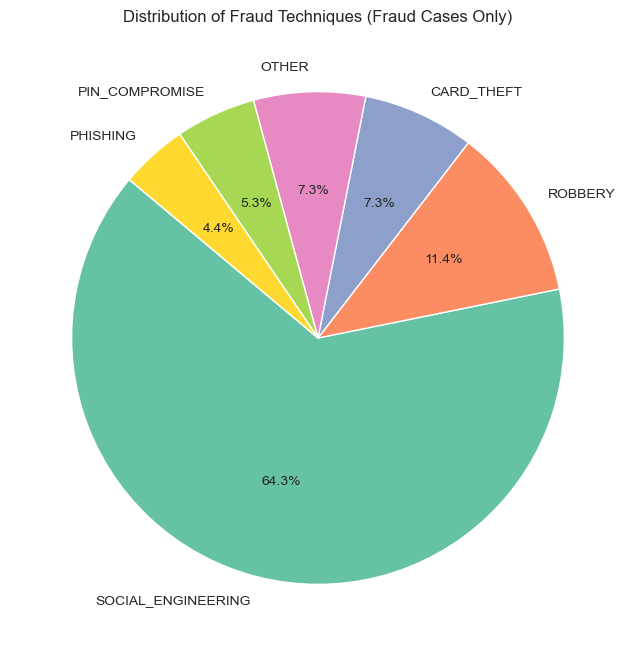

In [14]:
# Example: count fraud techniques
# Count fraud techniques (replace 'FraudTechnique' with your actual column name)
fraud_counts = df['fraud_technique'].value_counts()

# Remove "Legitimate" from the counts
fraud_counts = fraud_counts.drop('Legitimate', errors='ignore')

# Plot as pie chart
plt.figure(figsize=(8,8))
plt.pie(
    fraud_counts,
    labels=fraud_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Set2.colors
)
plt.title("Distribution of Fraud Techniques (Fraud Cases Only)")
plt.show()

In [15]:
channel_summary = df.groupby(['channel','is_fraud']).size().reset_index(name='count')
print(channel_summary)
# Displaying legitimate & fraud transaction 0 to 1

   channel  is_fraud   count
0      ATM         0   20053
1      ATM         1      22
2     ECOM         0   50151
3     ECOM         1      76
4       IB         0   99485
5       IB         1     168
6   Mobile         0  448026
7   Mobile         1    1496
8      POS         0  179484
9      POS         1     551
10     Web         0  199801
11     Web         1     687


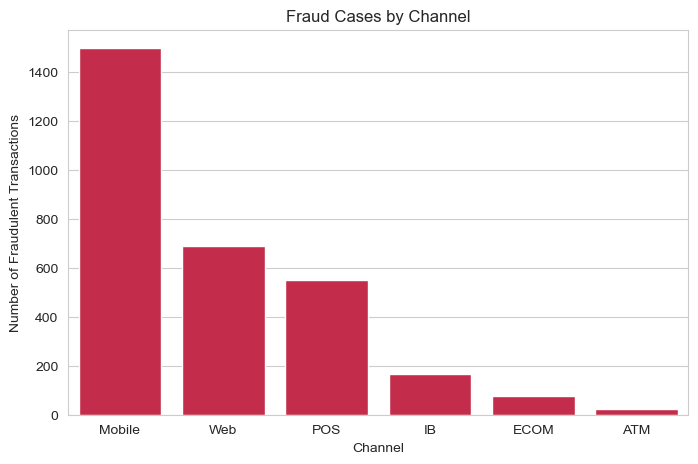

In [16]:
# Filter only fraud cases
fraud_only = df[df['is_fraud'] == 1]

# Count fraud cases per channel
fraud_counts = fraud_only['channel'].value_counts().reset_index()
fraud_counts.columns = ['channel', 'fraud_count']

# Plot fraud counts per channel
plt.figure(figsize=(8,5))
sns.barplot(x='channel', y='fraud_count', data=fraud_counts, color='crimson')

plt.title("Fraud Cases by Channel")
plt.xlabel("Channel")
plt.ylabel("Number of Fraudulent Transactions")
plt.show()

C:\Users\Judywealth\AppData\Local\Temp\ipykernel_13800\3589920718.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('RdYlGn_r')  # reversed Red-Yellow-Green


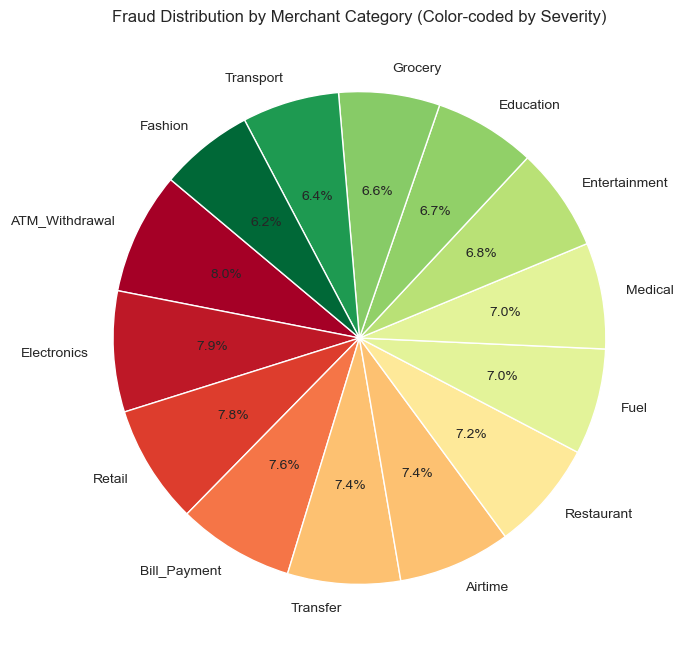

In [17]:
 # Filter only fraud cases
fraud_only = df[df['is_fraud'] == 1]

# Count fraud cases per merchant category
fraud_counts = fraud_only['merchant_category'].value_counts()

# Normalize fraud counts to range [0,1] for color mapping
norm = plt.Normalize(fraud_counts.min(), fraud_counts.max())

# Define a custom colormap: green → light red → dark red
from matplotlib import cm
cmap = cm.get_cmap('RdYlGn_r')  # reversed Red-Yellow-Green

colors = cmap(norm(fraud_counts.values))

# Plot pie chart
plt.figure(figsize=(8,8))
plt.pie(
    fraud_counts,
    labels=fraud_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors
)

plt.title("Fraud Distribution by Merchant Category (Color-coded by Severity)")
plt.show()


In [19]:
# Show the first 10 values in the column
print(df['day_of_week'].head(10))
# in the result, the first row represents days of the week, then the second row shows how many times it appears


0    5
1    1
2    6
3    1
4    2
5    2
6    2
7    2
8    3
9    0
Name: day_of_week, dtype: int64


In [20]:
# Keep only values 0–6 (assuming 0=Monday, 6=Sunday)
df = df[df['day_of_week'].isin(range(0,7))]

# Map numbers to day names
day_map = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

df['day_of_week'] = df['day_of_week'].map(day_map)


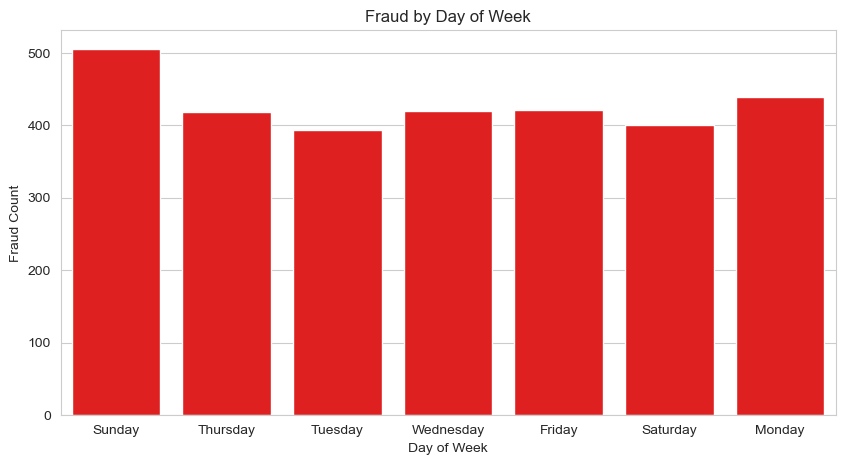

In [21]:
# Filter only fraud cases (assuming is_fraud == 1 means fraud)
fraud_only = df[df['is_fraud'] == 1]

plt.figure(figsize=(10,5))
sns.countplot(
    x='day_of_week',
    data=fraud_only,
    color='red'   # single color since only fraud is shown
)

plt.title('Fraud by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Fraud Count')
plt.show()

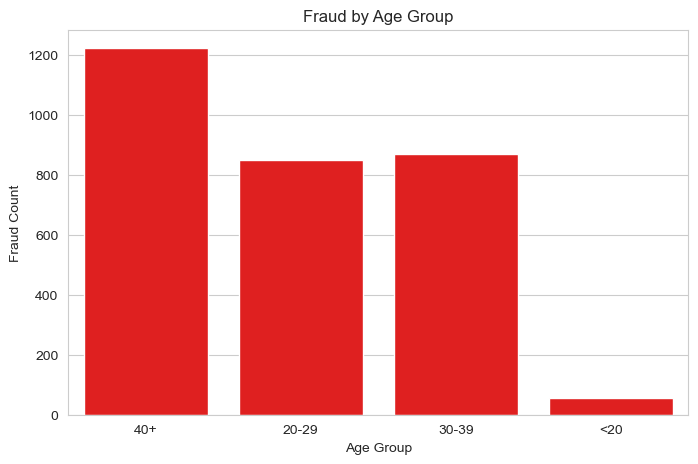

In [22]:
# Filter only fraud cases (assuming is_fraud == 1 means fraud)
fraud_only = df[df['is_fraud'] == 1]

plt.figure(figsize=(8,5))
sns.countplot(
    x='age_group',
    data=fraud_only,
    color='red'   # single color since only fraud is shown
)

plt.title('Fraud by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Fraud Count')
plt.show()

In [23]:
print(df['age_group'].unique())


['30-39' '40+' '20-29' '<20']


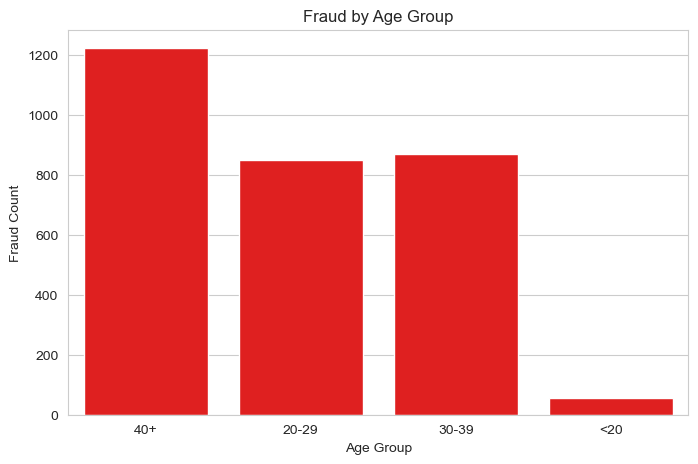

In [24]:
# Filter only fraud cases (assuming is_fraud == 1 means fraud)
fraud_only = df[df['is_fraud'] == 1]

plt.figure(figsize=(8,5))
sns.countplot(
    x='age_group',
    data=fraud_only,
    color='red'   # single color for fraud
)

plt.title('Fraud by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Fraud Count')
plt.show()

In [41]:
df.to_csv('nibss_fraud_cleaned.csv', index=False)
# saves your cleaned and analyzed dataset as a CSV file
# this file will be imported into Power BI for dashboard building
print('File exported successfully!')

File exported successfully!


In [42]:
import os
print(os.getcwd())


C:\Users\Judywealth
